## Heartbeat-classifier
Heartbeat classifier from MIT-BIH Arrythmia Database

In [1]:
from IPython.display import display
import wfdb
import numpy as np
from collections import Counter
from imblearn.over_sampling import RandomOverSampler

#### Dataset : MIT-BIH 
- 48 recordings of 30min -> each having 2 ECG signals
- 47 subjects (records 201, 202 from same subject)
- 23 normal recordings (100's files)
- 25 abnormal recordings (200's files)
- for each records, 3 files : signal file (.dat), header file (.hea), annotation file (.art) 


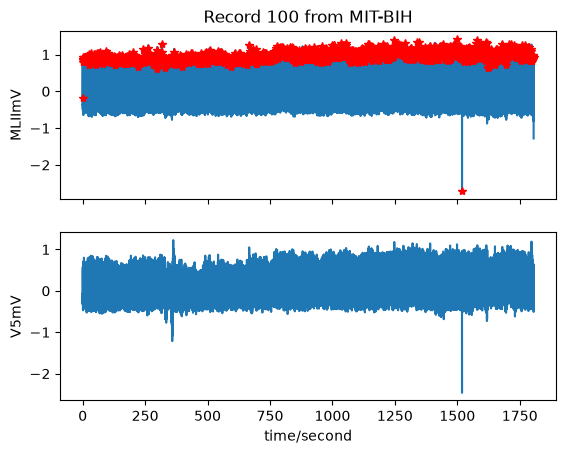

{'record_name': '100',
 'n_sig': 2,
 'fs': 360,
 'counter_freq': None,
 'base_counter': None,
 'sig_len': 650000,
 'base_time': None,
 'base_date': None,
 'comments': ['69 M 1085 1629 x1', 'Aldomet, Inderal'],
 'sig_name': ['MLII', 'V5'],
 'p_signal': array([[-0.145, -0.065],
        [-0.145, -0.065],
        [-0.145, -0.065],
        ...,
        [-0.675, -0.365],
        [-0.765, -0.335],
        [-1.28 ,  0.   ]], shape=(650000, 2)),
 'd_signal': None,
 'e_p_signal': None,
 'e_d_signal': None,
 'file_name': ['100.dat', '100.dat'],
 'fmt': ['212', '212'],
 'samps_per_frame': [1, 1],
 'skew': [None, None],
 'byte_offset': [None, None],
 'adc_gain': [200.0, 200.0],
 'baseline': [1024, 1024],
 'units': ['mV', 'mV'],
 'adc_res': [11, 11],
 'adc_zero': [1024, 1024],
 'init_value': [995, 1011],
 'checksum': [-22131, 20052],
 'block_size': [0, 0]}

{'record_name': '100',
 'extension': 'atr',
 'sample': array([    18,     77,    370, ..., 649484, 649734, 649991], shape=(2274,)),
 'symbol': ['+',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'A',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N',
  'N

In [2]:
record = wfdb.rdrecord('../../mitbih/100')
ann = wfdb.rdann('../../mitbih/100', 'atr')

wfdb.plot_wfdb(record=record, annotation=ann, title="Record 100 from MIT-BIH", time_units='seconds')
display(record.__dict__)
display(ann.__dict__)

## Detection of abnormal beat
The idea is to cut each signal into windows centered around each beat's peak and use 1D-CNN that slides along the signal to detect abnormal heatbeat. The annotations are used to label each window.

##### Preprocessing : 

In [3]:
# Separating patients in 2 sets (training, test sets), as in Chazal et al. 2004
training_patients = ['101', '106', '108', '109', '112', '114', '115', '116', '118', '119', '122', '124', '201', '203', '205', '207', '208', '209', '215', '220', '223', '230']
testing_patients = ['100', '103', '105', '111', '113', '117', '121', '123', '200', '202', '210', '212', '213', '214', '219', '221', '222', '228', '231', '232', '233', '234']

In [4]:
# Equivalence between MIT-BIH beat types and standard AAMI
# Link : https://www.researchgate.net/figure/Mapping-between-MIT-BIH-and-AAMI-labels_tbl1_348757037
 
dic = {'N' : ['N', '.', 'L', 'R', 'e', 'j'],
       'S' : ['A', 'a', 'J', 'S'],
       'V' : ['V', 'E'],
       'F' : ['F']
       }

dic = {'N' : 'N', '.' : 'N', 'L' : 'N', 'R' : 'N', 'e' : 'N', 'j' : 'N',
       'A' : 'S', 'a' : 'S', 'J' : 'S', 'S' : 'S',
       'V' : 'V', 'E' : 'V',
       'F' : 'F'}

class_idx = {'N' : 0, 'S' : 1, 'V' : 2, 'F' : 3} 

In [5]:
# Function to extract beats and label for one record
def extract_beats(record_nb, before=90, after=110):
    record_name = '../../mitbih/' + record_nb
    rec = wfdb.rdrecord(record_name)
    ann = wfdb.rdann(record_name, 'atr') #ann.sample has the beat peak indexes, ann.symbol has the corresponding MIT-BIH beat type
    channel = np.where(np.array(rec.sig_name) == "MLII")
    sig = rec.p_signal[:, channel[0]]

    beats, types = [],[]
    for peak, symbol in zip(ann.sample, ann.symbol):
        if symbol not in dic :
            continue
        if peak - before < 0 or peak + after > len(sig) : 
            continue
        beat = sig[peak-before : peak+after]
        type = class_idx[dic[symbol]]
        beats.append(beat)
        types.append(type)

    return np.array(beats), np.array(types)
    

beats, types = extract_beats('100')
print(beats.shape) #(Nb of relevant beats x length of the window (with default, supposed to be 200) x 1 ) -> each window around a relevant beat is a 1d array, and you have as many of them as relevant beat

(2271, 200, 1)


In [8]:
# Creating the datasets
def build_datasets(record_nbs): 
    X, y = [],[]
    for record_nb in record_nbs : 
        beats, types = extract_beats(record_nb)
        X.append(beats)
        y.append(types)
    return np.concatenate(X), np.concatenate(y)

X_train, y_train = build_datasets(training_patients)
X_test, y_test = build_datasets(testing_patients)

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)


(51000, 200, 1) (51000,)
(49690, 200, 1) (49690,)


In [9]:
# UpSampling the minority classes (to half of the majority class)
print(f"Original class distribution in training set: {Counter(y_train)}")

nb_beats, window_size, c = X_train.shape
X_flat = X_train.reshape(nb_beats, -1) #flatten to make augmentation work

max_class = max(Counter(y_train).values())
ros = RandomOverSampler(sampling_strategy={0: max_class, 1 : int(0.5*max_class), 2 : int(0.5*max_class), 3: int(0.5*max_class) }, random_state=42)
X_flat, y_resampled = ros.fit_resample(X_flat, y_train)

X_train_resampled, y_train_resampled = X_flat.reshape(-1,window_size,c), y_resampled
print(f"After resampling class distribution in training set : {Counter(y_train_resampled)}")


Original class distribution in training set: Counter({np.int64(0): 45854, np.int64(2): 3788, np.int64(1): 944, np.int64(3): 414})
After resampling class distribution in training set : Counter({np.int64(0): 45854, np.int64(1): 22927, np.int64(2): 22927, np.int64(3): 22927})


##### Training :


In [10]:
import torch 
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
# CNN expects : (batch, channel, length) but we have (nb_beats, window_size, 1) where window_size is the length of the signal, and 1 is the single channel, 
# To do : transform sets into tensors, transform the dimensions, and creates batches (Dataloader)
# We do it with both : unmodified training set (adding class weight after), and resample training set (no adding class weight after)

# 1. Tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32).permute(0,2,1)
y_train_t = torch.tensor(y_train, dtype=torch.long)
print(X_train_t.shape)
X_train_resampled_t = torch.tensor(X_train_resampled, dtype=torch.float32).permute(0,2,1)
y_train_resampled_t = torch.tensor(y_train_resampled, dtype=torch.long)

X_test_t = torch.tensor(X_test, dtype=torch.float32).permute(0,2,1)
y_test_t = torch.tensor(y_test, dtype=torch.long)

# 2. Datasets
train_dataset = TensorDataset(X_train_t, y_train_t)
train_resampled_dataset = TensorDataset(X_train_resampled_t, y_train_resampled_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

# 3. Dataloader
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
train_resampled_loader = DataLoader(train_resampled_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)


torch.Size([51000, 1, 200])


In [12]:
# Network
# When entering the network, a sample is of size  : (batch, channel=1, length=window_size)
class BeatCNN(nn.Sequential):
    def __init__(self, n_classes=4):
        super().__init__(
            # Conv and pooling layers
            nn.Conv1d(1, 16, kernel_size=5),
            nn.BatchNorm1d(16), # Normalize over the batch (mean 0, var 1)
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(16, 32, kernel_size=5),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(32, 64, kernel_size=3),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(output_size=1), # Averages each cannel over the length (batch, channel=64, length=window_size) -> (batch, channel=64, 1)

            nn.Flatten(), #(batch, 64, 1) -> (batch, 64)

            # Linear layers
            nn.Linear(64, n_classes),
        )

In [ ]:
# Training fct 
def train(num_epochs, train_loader, test_loader, network, criterion, optimizer, device, target_names = ["Normal", "S-beat", "V-beat", "F-beat"]):

    for i in range(num_epochs):
        print(f"Epoch number {i+1} starting")

        network.train()
        for x, y in train_loader : 
            x, y = x.to(device), y.to(device)
            y_pred = network(x)

            optimizer.zero_grad()
            loss = criterion(y_pred, y)
            loss.backward()
            optimizer.step()

        # Eval once per epoch
        network.eval()
        pred_classes = []
        true_classes = []
        with torch.no_grad():
            for x, y in test_loader :
                x, y = x.to(device), y.to(device)
                y_pred = network(x) #network outputs proba per class
                y_pred_class = y_pred.argmax(1)  # class is the most probable one
                pred_classes.append(y_pred_class)
                true_classes.append(y)

        pred_classes = torch.cat(pred_classes).cpu().numpy()
        true_classes = torch.cat(true_classes).cpu().numpy()
        print(classification_report(y_true=true_classes, y_pred=pred_classes, target_names=target_names))
        cm = confusion_matrix(y_true=true_classes, y_pred=pred_classes)
        """
        plt.figure(figsize=(6,5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=[f"{class_name}" for class_name in target_names],
                    yticklabels=[f"{class_name}" for class_name in target_names]
                )
        plt.xlabel("Predicted label")
        plt.ylabel("True label")
        plt.show()
        """

In [ ]:
# Training loop for unmodified training set

# GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device : {device}")
device = torch.device(device)

# Net init
net = BeatCNN(n_classes=4)
net.to(device)

# Weighted classes
w = compute_class_weight("balanced", classes=np.array([0,1,2,3]), y=y_train)
weights = torch.tensor(w, dtype=torch.float32).to(device)
criterion= nn.CrossEntropyLoss(weight=weights) 

# Optimizer
optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

train(20, train_loader, test_loader, net, criterion, optimizer, device)




Device : cpu
Epoch number 1 starting
              precision    recall  f1-score   support

      Normal       0.97      0.49      0.65     44245
      S-beat       0.09      0.89      0.16      1837
      V-beat       0.81      0.71      0.76      3220
      F-beat       0.02      0.25      0.03       388

    accuracy                           0.52     49690
   macro avg       0.47      0.59      0.40     49690
weighted avg       0.92      0.52      0.63     49690

Epoch number 2 starting
              precision    recall  f1-score   support

      Normal       0.97      0.81      0.88     44245
      S-beat       0.17      0.69      0.28      1837
      V-beat       0.70      0.83      0.76      3220
      F-beat       0.00      0.01      0.00       388

    accuracy                           0.80     49690
   macro avg       0.46      0.58      0.48     49690
weighted avg       0.91      0.80      0.84     49690

Epoch number 3 starting
              precision    recall  f1-score  

In [112]:
# Training loop for balanced dataset 

# GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device : {device}")
device = torch.device(device)

# Net init
net = BeatCNN(n_classes=4)
net.to(device)

# No weighted classes
criterion= nn.CrossEntropyLoss() 

# Optimizer
optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

train(1, train_loader, test_loader, net, criterion, optimizer)


Device : cpu
Epoch number 1 starting
Epoch 1 : test accuracy = 0.890
